# Baseline y variantes de datos

**Objetivo:** fijar una referencia mínima (baseline) y medir si **cambiar los datos** —no el modelo— la mejora de forma demostrable.

| Pieza | Qué es |
|---|---|
| **Baseline** | `dummy` (clase mayoritaria), `kNN` (k = 5) y `Naive Bayes` sobre las variables originales (A), con imputación y escalado |
| **V1 — número de vistas** | 1 vista (0°), 2 vistas (0°+180°), 4 ecuatoriales (sin pedúnculo) y 5 vistas (baseline). Las features se re-agregan por fruto usando solo esas vistas |
| **V2 — balanceo** | sobremuestreo y submuestreo de las clases **solo en train** (dentro del ajuste, nunca antes de partir) |

**Protocolo:** misma partición congelada y mismos pliegues que Feature Engineering → comparaciones **pareadas**. CV estratificada solo sobre train + evaluación en val; **TEST no se toca**. Variante vs baseline: prueba t corregida para CV repetida (Nadeau & Bengio, 2003) con corrección de Holm. Métrica central: F1 macro; se reporta a la par el F1, recall y PR-AUC de **Fábrica**.

> Con `MODO_DEMO = True` se usan imágenes sintéticas: sirve para validar el flujo, **no** para sacar conclusiones.

**Qué cubre de la tesis**
| Tesis | Aquí |
|---|---|
| Métricas de la categoría final (4.6.4): F1 macro, exactitud balanceada, **kappa**, recall de Fábrica | §2–3 (kappa y F1 por clase añadidos) |
| Hipótesis general: F1 macro ≥ 0,90, recall de Fábrica ≥ 0,90, κ ≥ 0,80, con **IC95 % por bootstrap pareado (B = 1000)** y límite inferior ≥ umbral | §3b |
| **H3 / E4:** defectos de Fábrica que pasan sin detectarse con 1 vista (0°) frente a 5 vistas, **McNemar** | §4b |
| **H4 / E1:** línea base *sin* preprocesamiento: F1 de color/madurez y F1 del par Primera–Segunda | §4c |
| **H5 / E3:** F1 de Tercera y Fábrica con y sin balanceo | §4d |
| Control de atajo (4.3): la categoría no debe poder adivinarse por la sesión de captura | §0 |

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import modelo_baseline as mb, fe_experimentos as fx, extraer_features as ef, ingesta, particion, informe
from src.remuestreo import indices_remuestreo

MODO_DEMO = False                      # <-- False con los datos reales
RAW  = ROOT / "data" / ("demo/raw" if MODO_DEMO else "raw")
PROC = ROOT / "data" / ("demo/processed" if MODO_DEMO else "processed")
cfg = mb.cargar_cfg_baseline()
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .25})
print({k: cfg[k] for k in ("semillas", "cv_folds", "modelos", "positivo", "metrica_central")})
print("Variantes de vistas:", cfg["variantes"]["vistas"], "| remuestreo:", cfg["variantes"]["remuestreo"])

{'semillas': [0, 1, 2], 'cv_folds': 5, 'modelos': ['dummy', 'knn', 'gnb'], 'positivo': 'Fabrica', 'metrica_central': 'f1_macro'}
Variantes de vistas: {'1vista': ['0'], '2vistas': ['0', '180'], '4ecuatoriales': ['0', '90', '180', '270']} | remuestreo: ['sobre', 'sub']


## 0. Control de atajo por sesión (léelo antes que los resultados)
Se mide cuánto se puede acertar **sin mirar el fruto**: un clasificador que solo conoce la sesión (lote × fecha). Si los modelos solo superan ese piso por poco, el baseline está aprendiendo el contexto.

In [2]:
from src import evidencia_hipotesis as eh, estadistica as est
from src.fe_columnas import columnas_para
_df = fx.cargar_datos(PROC, ef.cargar_cfg()) if (PROC / "features_frutos.csv").exists() else None
if _df is not None:
    ATAJO = eh.atajo_sesion(_df, columnas_para({"A"}))
    print(f"Solo con la sesión ({ATAJO['n_sesiones']} sesiones): F1 macro = {ATAJO['f1_macro_por_sesion']:.3f}, kappa = {ATAJO['kappa_por_sesion']:.3f}, recall Fábrica = {ATAJO['recall_fabrica_por_sesion']:.2f}")
    print(f"Las variables de imagen identifican la sesión con exactitud {ATAJO['exactitud_sesion_desde_features']:.2f} | referencia dummy ≈ 0.07")

Solo con la sesión (4 sesiones): F1 macro = 0.733, kappa = 0.753, recall Fábrica = 1.00
Las variables de imagen identifican la sesión con exactitud 0.90 | referencia dummy ≈ 0.07


## 1. Datos (se generan los prerrequisitos que falten)

In [3]:
if not (PROC / "indice_frutos.csv").exists():  ingesta.main(RAW, PROC)
if not (PROC / "particion.csv").exists():      particion.main(PROC, forzar=False)      # se crea una vez y queda congelada
if not (PROC / "features_frutos.csv").exists(): ef.main(RAW, PROC, n_jobs=1)
df = fx.cargar_datos(PROC, ef.cargar_cfg())
tr, va, te = fx.dividir(df)
cuenta = tr["y"].value_counts()
HAY_CLASES = len(cuenta) >= 2 and cuenta.min() >= 5
print(f"Frutos train/val/test: {len(tr)}/{len(va)}/{len(te)}")
display(pd.crosstab(df["y"], df["subset"])[["train", "val", "test"]])
if not HAY_CLASES:
    print("[AVISO] Se necesitan al menos 2 categorías con >= 5 frutos en train: se omiten las secciones 2 a 5.")

Frutos train/val/test: 359/76/76


subset,train,val,test
y,,,
Extra,77,16,16
Fabrica,70,15,15
Primera,71,15,15
Segunda,71,15,15
Tercera,70,15,15


## 2. Ejecutar baseline y variantes
Cada configuración se evalúa con 5 pliegues × 3 semillas sobre train (más una evaluación en val) y todo queda registrado en `logs/baseline_runs/<corrida>/` y `logs/metrics_baseline.txt`.

In [4]:
if HAY_CLASES:
    res, comp, RUN_ID = mb.ejecutar(PROC, cfg, verbose=False)
    print("Corrida registrada:", RUN_ID)
    print(mb.tabla_baseline_md(res))

Corrida registrada: 20261106_182044
| Modelo | CV F1 macro | CV kappa | CV F1 Fábrica | CV recall Fábrica | CV PR-AUC Fábrica | VAL F1 macro | VAL kappa | VAL F1 Fábrica | ajuste (s) | latencia (ms/fruto) |
|---|---|---|---|---|---|---|---|---|---|---|
| dummy | 0.071 ± 0.002 | 0.000 ± 0.000 | 0.000 ± 0.000 | 0.000 ± 0.000 | 0.195 ± 0.001 | 0.070 | 0.000 | 0.000 | 0.01 | 834 |
| knn | 0.866 ± 0.048 | 0.834 ± 0.059 | 0.863 ± 0.077 | 0.767 ± 0.116 | 0.947 ± 0.045 | 0.908 | 0.885 | 0.889 | 0.01 | 835 |
| gnb | 0.745 ± 0.089 | 0.689 ± 0.107 | 0.758 ± 0.080 | 0.681 ± 0.080 | 0.864 ± 0.076 | 0.811 | 0.769 | 0.720 | 0.01 | 834 |



## 3. Baseline
**Qué buscar:** (1) que cualquier modelo supere con claridad al *dummy* (si no, las variables no aportan); (2) el recall y PR-AUC de Fábrica, la clase crítica; (3) el tamaño de la desviación ± entre pliegues: con pocos frutos es grande y limita lo que se puede concluir.

In [5]:
if HAY_CLASES:
    b = res[res.variante == "BASE"].set_index("modelo")
    show = pd.DataFrame({"CV F1 macro": [mb._ms(r, "f1_macro") for _, r in b.iterrows()],
                         "CV kappa": [mb._ms(r, "kappa") for _, r in b.iterrows()],
                         "CV F1 Fábrica": [mb._ms(r, "f1_pos") for _, r in b.iterrows()],
                         "CV recall Fábrica": [mb._ms(r, "recall_pos") for _, r in b.iterrows()],
                         "VAL F1 macro": b.val_f1_macro.round(3), "VAL kappa": b.val_kappa.round(3)}, index=b.index)
    display(show)
    mejor = b.drop(index="dummy").cv_f1_macro_media.idxmax()
    cm = pd.read_json(sorted((ROOT / "logs/baseline_runs").glob("*"))[-1] / "matrices_confusion_val.json")
    m = cm[f"BASE|{mejor}"]; lab = m["labels"]
    display(pd.DataFrame(m["matriz"], index=[f"real {x}" for x in lab], columns=[f"pred {x}" for x in lab]))

,CV F1 macro,CV kappa,CV F1 Fábrica,CV recall Fábrica,VAL F1 macro,VAL kappa
modelo,,,,,,
dummy,0.071 ± 0.002,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.070,0.000
knn,0.866 ± 0.048,0.834 ± 0.059,0.863 ± 0.077,0.767 ± 0.116,0.908,0.885
gnb,0.745 ± 0.089,0.689 ± 0.107,0.758 ± 0.080,0.681 ± 0.080,0.811,0.769


,pred Extra,pred Fabrica,pred Primera,pred Segunda,pred Tercera
real Extra,15,0,0,1,0
real Fabrica,0,12,3,0,0
real Primera,0,0,14,0,1
real Segunda,1,0,0,14,0
real Tercera,1,0,0,0,14


## 3b. Metas de la hipótesis general con IC bootstrap pareado (B = 1000)
La tesis (4.6.4) exige que el **límite inferior** del IC95 % cumpla el umbral. Se aplica a las predicciones del mejor baseline en **validación** (no TEST). Es **informativo**: modelo clásico, 76 frutos y posible atajo de sesión.

In [7]:
if HAY_CLASES:
    d_run = sorted((ROOT / "logs/baseline_runs").glob("*"))[-1]
    pv = pd.read_csv(d_run / "predicciones_val.csv", dtype=str)
    y = pv["y"].to_numpy(); pred = pv[f"BASE|{mejor}"].to_numpy()
    metas = [("F1 macro", lambda a, p: est.metricas_tesis(a, p)["f1_macro"], .90), ("Recall de Fábrica", lambda a, p: est.recall_clase(a, p, "Fabrica"), .90),
             ("Kappa de Cohen", est.kappa_cohen, .80)]
    filas = []
    for nombre, f, u in metas:
        ic = est.bootstrap_pareado(y, pred, metrica=f, B=1000)
        filas.append(dict(indicador=nombre, meta=u, estimado=ic["estimado"], IC95_inf=ic["ic_inf"], IC95_sup=ic["ic_sup"], lectura=est.verifica_umbral_ic(ic, u)))
    print(f"Mejor baseline: {mejor} | n = {len(y)} frutos de VAL"); display(pd.DataFrame(filas).round(3))
    if _df is not None: print(f"Piso 'solo sesión': F1 macro {ATAJO['f1_macro_por_sesion']:.3f} (si el modelo no lo supera con claridad, la meta no demuestra nada).")

Mejor baseline: knn | n = 76 frutos de VAL


,indicador,meta,estimado,IC95_inf,IC95_sup,lectura
0,F1 macro,0.9,0.908,0.834,0.968,estimado >= umbral pero IC inf < umbral
1,Recall de Fábrica,0.9,0.800,0.562,1.000,no cumple
2,Kappa de Cohen,0.8,0.885,0.800,0.966,cumple (IC inf >= umbral)


Piso 'solo sesión': F1 macro 0.733 (si el modelo no lo supera con claridad, la meta no demuestra nada).


## 4. Variantes de datos vs baseline
**Cómo leer:** Δ = diferencia media pareada por pliegue. `veredicto` solo dice *mejora* o *empeora* si el p ajustado por Holm es < 0,05; en otro caso **no hay evidencia**, aunque la media sea distinta. Con decenas de frutos, diferencias de 0,05–0,10 en F1 son ruido.

,modelo,variante,dif_media,pliegues_mejoran_pct,p_holm,veredicto
0,gnb,V1_1vista,-0.299,0.000,0.000,empeora
1,gnb,V1_2vistas,-0.102,0.000,0.266,sin evidencia
2,gnb,V1_4ecuatoriales,-0.042,13.333,1.000,sin evidencia
3,gnb,V2_sobremuestreo,-0.006,33.333,1.000,sin evidencia
4,gnb,V2_submuestreo,0.001,20.000,1.000,sin evidencia
5,knn,V1_1vista,-0.051,0.000,0.534,sin evidencia
6,knn,V1_2vistas,-0.021,20.000,1.000,sin evidencia
7,knn,V1_4ecuatoriales,0.004,53.333,1.000,sin evidencia
8,knn,V2_sobremuestreo,-0.008,20.000,1.000,sin evidencia
9,knn,V2_submuestreo,0.002,20.000,1.000,sin evidencia


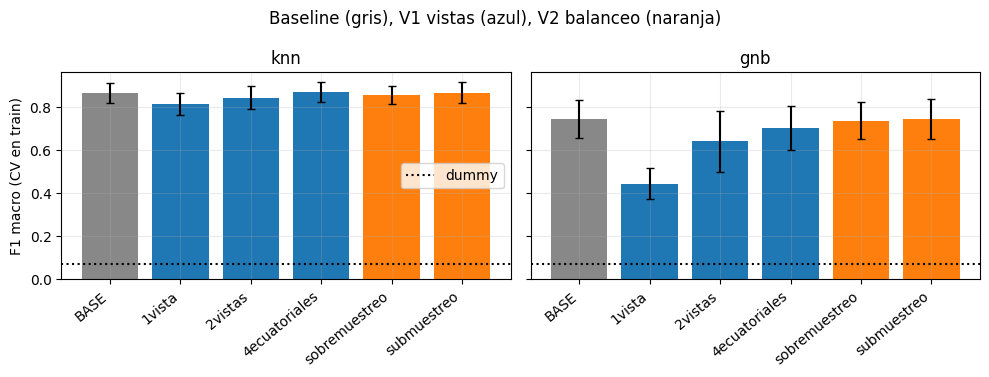

In [8]:
if HAY_CLASES:
    k = comp.pivot_table(index=["modelo", "variante"], columns="metrica", values=["dif_media", "p_holm"]).round(3)
    v = comp[comp.metrica == "f1_macro"][["modelo", "variante", "dif_media", "pliegues_mejoran_pct", "p_holm", "veredicto"]].round(3)
    display(v.sort_values(["modelo", "variante"]).reset_index(drop=True))

    orden = ["BASE", "V1_1vista", "V1_2vistas", "V1_4ecuatoriales", "V2_sobremuestreo", "V2_submuestreo"]
    col = {"BASE": "#888", "V1": "#1f77b4", "V2": "#ff7f0e"}
    mods = [m for m in cfg["modelos"] if m != "dummy"]
    fig, axs = plt.subplots(1, len(mods), figsize=(5 * len(mods), 3.8), sharey=True, squeeze=False)
    dummy = res.loc[res.modelo == "dummy", "cv_f1_macro_media"].iloc[0]
    for ax, m in zip(axs[0], mods):
        s = res[res.modelo == m].set_index("variante").reindex(orden)
        ax.bar(range(len(s)), s.cv_f1_macro_media, yerr=s.cv_f1_macro_std, capsize=3,
               color=[col["BASE"] if x == "BASE" else col[x[:2]] for x in s.index])
        ax.axhline(dummy, color="k", ls=":", label="dummy"); ax.set_title(m)
        ax.set_xticks(range(len(s))); ax.set_xticklabels([x.replace("V1_", "").replace("V2_", "") for x in s.index], rotation=40, ha="right")
    axs[0][0].set_ylabel("F1 macro (CV en train)"); axs[0][0].legend()
    plt.suptitle("Baseline (gris), V1 vistas (azul), V2 balanceo (naranja)"); plt.tight_layout(); plt.show()

## 4b. H3 / E4 — ¿cinco vistas reducen los defectos que pasan sin detectarse?
Referencia: frutos de **Fábrica por defecto** (categoría Fábrica y severidad del panel ≥ 0,5). Detector "basta una vista" (Tabla 3.3): marca el fruto si alguna vista usada supera la fracción de superficie con defecto. Se compara **0°** con las **5 vistas** sobre los mismos frutos (train + val) con **McNemar**. Meta de H3: reducción ≥ 15 puntos porcentuales.

Frutos de Fábrica por defecto: 74
Omitidos con 1 vista (0°): 50.0 %  IC95 Wilson 39–61
Omitidos con 5 vistas:     47.3 %  IC95 Wilson 36–59
Reducción: 2.7 pp (meta ≥ 15) | McNemar exacta: discordantes 2/0, p = 0.500 -> NO cumple H3 con este detector


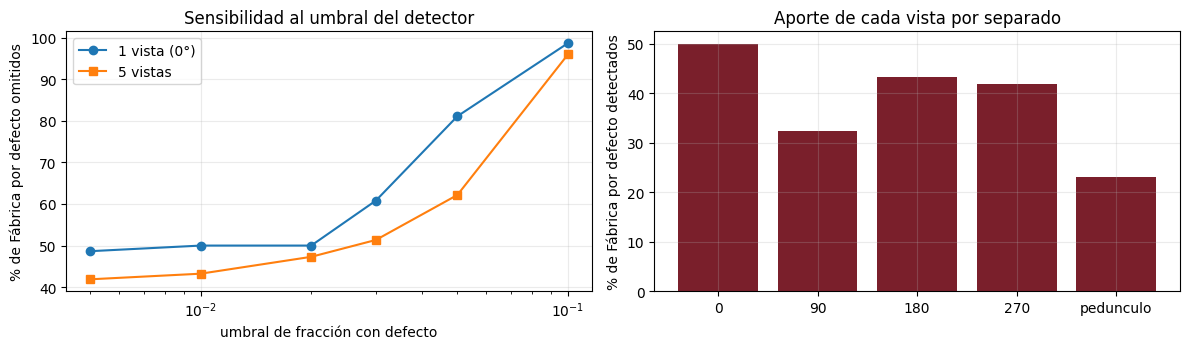

,theta_ratio,omitidos_1vista_pct,omitidos_5vistas_pct,reduccion_pp,p_mcnemar
0,0.005,48.649,41.892,6.757,0.062
1,0.010,50.000,43.243,6.757,0.062
2,0.020,50.000,47.297,2.703,0.500
3,0.030,60.811,51.351,9.459,0.016
4,0.050,81.081,62.162,18.919,0.000
5,0.100,98.649,95.946,2.703,0.500


Lectura: aunque las 5 vistas ayudan algo, el detector clásico deja pasar casi la mitad aun con todas las vistas: el límite es la extracción del defecto, no el número de vistas.


In [9]:
vistas_df = pd.read_csv(PROC / "features_vistas.csv", dtype={"id_fruto": str, "lote": str, "fecha": str, "vista": str})
fr_idx = pd.read_csv(PROC / "indice_frutos.csv", dtype={"id_fruto": str, "lote": str, "fecha": str}).merge(
    pd.read_csv(PROC / "particion.csv", dtype={"id_fruto": str}), on="id_fruto")
E4 = eh.e4_defectos_omitidos(vistas_df, fr_idx, subconjuntos=["train", "val"])
mc = E4["mcnemar"]
print(f"Frutos de Fábrica por defecto: {E4['n_fabrica_defecto']}")
print(f"Omitidos con 1 vista (0°): {E4['pct_omitidos_1vista']:.1f} %  IC95 Wilson {E4['ic_1vista'][0]:.0f}–{E4['ic_1vista'][1]:.0f}")
print(f"Omitidos con 5 vistas:     {E4['pct_omitidos_5vistas']:.1f} %  IC95 Wilson {E4['ic_5vistas'][0]:.0f}–{E4['ic_5vistas'][1]:.0f}")
print(f"Reducción: {E4['reduccion_pp']:.1f} pp (meta ≥ 15) | McNemar {mc['prueba']}: discordantes {mc['b']}/{mc['c']}, p = {mc['p']:.3f} -> {'CUMPLE H3' if E4['cumple'] else 'NO cumple H3 con este detector'}")
bar = eh.e4_barrido_umbrales(vistas_df, fr_idx, subconjuntos=["train", "val"]); pv_ = eh.e4_por_vista(vistas_df, fr_idx, subconjuntos=["train", "val"])
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
axs[0].plot(bar.theta_ratio, bar.omitidos_1vista_pct, "o-", label="1 vista (0°)"); axs[0].plot(bar.theta_ratio, bar.omitidos_5vistas_pct, "s-", label="5 vistas")
axs[0].set_xscale("log"); axs[0].set_xlabel("umbral de fracción con defecto"); axs[0].set_ylabel("% de Fábrica por defecto omitidos"); axs[0].legend(); axs[0].set_title("Sensibilidad al umbral del detector")
axs[1].bar(pv_.vista, pv_.pct_detectados, color="#7a1f2b"); axs[1].set_ylabel("% de Fábrica por defecto detectados"); axs[1].set_title("Aporte de cada vista por separado")
plt.tight_layout(); plt.show(); display(bar.round(3))
print("Lectura: aunque las 5 vistas ayudan algo, el detector clásico deja pasar casi la mitad aun con todas las vistas: el límite es la extracción del defecto, no el número de vistas.")

## 4c. H4 / E1 — línea base sin corrección de brillo y color
E1 debe sumar **+5 puntos** al F1 de color/madurez y **+3** al del par Primera–Segunda frente a un modelo idéntico *sin* preprocesamiento. Aquí se fija esa referencia (con CV fuera de muestra en train). Cuando exista `preprocesamiento.py` (carta de color), se repite idéntico y se compara.

In [10]:
if HAY_CLASES:
    H4 = eh.h4_linea_base(tr, columnas_para({"A"}))
    print(f"F1 macro de color/madurez (clases del panel {H4['clases_color']}): {H4['f1_color']:.3f} ± {H4['f1_color_std']:.3f}")
    print(f"F1 macro del par Primera–Segunda (n = {H4['n_par']}): {H4['f1_primera_segunda']:.3f} ± {H4['f1_primera_segunda_std']:.3f}")
    print("Atención: Primera y Segunda provienen de sesiones distintas en estos datos, así que este F1 puede ser en parte el de la sesión (§0); E1 solo es interpretable con sesiones mezcladas.")
    print("Metas de E1: color/madurez +0.05 y Primera–Segunda +0.03 sobre estos valores (pendiente: src/preprocesamiento.py).")

F1 macro de color/madurez (clases del panel {'verde': 328, 'amarillo': 26, 'verde_amarillo': 5}): 0.618 ± 0.069
F1 macro del par Primera–Segunda (n = 142): 0.969 ± 0.004
Atención: Primera y Segunda provienen de sesiones distintas en estos datos, así que este F1 puede ser en parte el de la sesión (§0); E1 solo es interpretable con sesiones mezcladas.
Metas de E1: color/madurez +0.05 y Primera–Segunda +0.03 sobre estos valores (pendiente: src/preprocesamiento.py).


## 4d. H5 / E3 — F1 de Tercera y Fábrica con y sin balanceo
H5 pide **+8 puntos** de F1 en Tercera y en Fábrica. Aquí solo existen sobre/submuestreo; pesos de clase están en `Hiperparametros.ipynb`, y focal loss y aumento dirigido requieren el modelo profundo.

In [11]:
if HAY_CLASES:
    h5 = eh.h5_por_clase(res, comp)
    display(h5.round(3))
    print("Meta H5: Δ ≥ +0.08 en F1 Tercera y F1 Fábrica. Las diferencias con p Holm ≥ 0.05 (§4) no son demostrables.")

,modelo,variante,F1 Tercera,F1 Fabrica,Δ F1 Tercera,Δ F1 Fabrica
0,knn,BASE,0.845,0.863,0.000,0.000
1,knn,V2_sobremuestreo,0.824,0.864,-0.021,0.000
2,knn,V2_submuestreo,0.843,0.869,-0.002,0.005
3,gnb,BASE,0.584,0.758,0.000,0.000
4,gnb,V2_sobremuestreo,0.569,0.748,-0.015,-0.010
5,gnb,V2_submuestreo,0.587,0.761,0.004,0.003


Meta H5: Δ ≥ +0.08 en F1 Tercera y F1 Fábrica. Las diferencias con p Holm ≥ 0.05 (§4) no son demostrables.


## 5. Costo de las variantes y qué hace el remuestreo
- **Vistas:** menos imágenes por fruto = captura y extracción más rápidas. El gráfico enfrenta F1 con la latencia de extracción (medida aquí; solo features).
- **Balanceo:** muestra cuántos frutos ve el modelo en train antes y después del remuestreo.

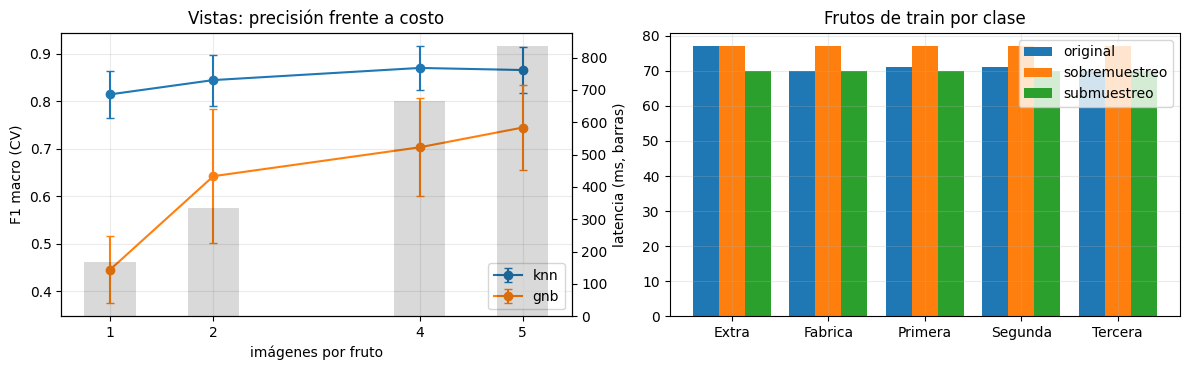

Latencia por fruto (ms): {1: 167.0, 2: 333.0, 4: 665.0, 5: 834.0}


In [12]:
if HAY_CLASES:
    nv = {"BASE": 5, "V1_4ecuatoriales": 4, "V1_2vistas": 2, "V1_1vista": 1}
    vs = res[res.variante.isin(nv)].assign(nv=lambda d: d.variante.map(nv))
    fig, axs = plt.subplots(1, 2, figsize=(12, 3.8)); ax2 = axs[0].twinx()
    for m in mods:
        s = vs[vs.modelo == m].sort_values("nv")
        axs[0].errorbar(s.nv, s.cv_f1_macro_media, yerr=s.cv_f1_macro_std, marker="o", capsize=3, label=m)
    l = vs[vs.modelo == mods[0]].sort_values("nv"); ax2.bar(l.nv, l.latencia_total_ms_fruto, width=.5, alpha=.15, color="k")
    axs[0].set_xlabel("imágenes por fruto"); axs[0].set_ylabel("F1 macro (CV)"); ax2.set_ylabel("latencia (ms, barras)"); ax2.grid(False)
    axs[0].set_xticks(sorted(nv.values())); axs[0].legend(); axs[0].set_title("Vistas: precisión frente a costo")
    y = tr["y"].to_numpy(); cats = sorted(set(y)); w = .27
    for i, (nom, idx) in enumerate([("original", np.arange(len(y))), ("sobremuestreo", indices_remuestreo(y, "sobre")),
                                    ("submuestreo", indices_remuestreo(y, "sub"))]):
        axs[1].bar(np.arange(len(cats)) + i * w, [(y[idx] == c).sum() for c in cats], w, label=nom)
    axs[1].set_xticks(np.arange(len(cats)) + w); axs[1].set_xticklabels(cats); axs[1].legend(); axs[1].set_title("Frutos de train por clase")
    plt.tight_layout(); plt.show()
    print("Latencia por fruto (ms):", vs.groupby("nv").latencia_total_ms_fruto.mean().round(0).to_dict())

## 6. Decisiones (completar con datos reales)
| # | Pregunta | Evidencia | Decisión |
|---|---|---|---|
| 1 | ¿El baseline supera con claridad al dummy? ¿En Fábrica? | §3 | |
| 2 | ¿Usar menos vistas pierde precisión demostrable? ¿Cuánto cuesta cada vista? | §4–5 | |
| 3 | ¿El balanceo mejora con evidencia (p Holm < 0,05)? ¿O conviene recolectar más frutos? | §4–5 | |
| 4 | ¿Qué configuración de datos se usa en el siguiente paso (MVCNN y multitarea)? | §4 | |
| 5 | ¿Qué limitaciones de los datos condicionan estas conclusiones (clases chicas, color sin corregir)? | EDA / FE | |

## 7. Generar el informe
Reúne datos, EDA, Feature Engineering, baseline y variantes en un documento Word y un Markdown con las cifras reales de esta corrida.

In [12]:
if HAY_CLASES:
    _img0 = imgs0 = pd.read_csv(PROC / "indice_imagenes.csv", nrows=1)["ruta"].iloc[0].replace("\\", "/")
    if not ((ROOT / _img0).exists() or Path(_img0).exists()):
        print("Se omite la regeneración del informe: faltan las imágenes originales en data/raw/imagenes (el EDA del informe las lee).")
    else:
        r = informe.generar(PROC, ROOT / ("informe_demo" if MODO_DEMO else "informe"))
        print("Informe generado:", r["docx"])

Se omite la regeneración del informe: faltan las imágenes originales en data/raw/imagenes (el EDA del informe las lee).
